# Analysis
## 08 – Multivariate Kettenregel, Jacobi- und Hesse-Matrix
Von einzelnen Steigungen zur vollständigen Beschreibung mehrdimensionaler Änderungen

Im vorigen Abschnitt haben wir gelernt, wie man partielle Ableitungen berechnet und zum Gradienten zusammensetzt. Aber dort hatten die Variablen $x$ und $y$ keine eigene Abhängigkeit - sie waren „frei". In der Realität ist das selten der Fall:

- Die **Temperatur** $T(x, y)$ in einem Raum hängt von der Position ab, und die Position $(x(t), y(t))$ ändert sich mit der Zeit, wenn Du Dich bewegst. Wie schnell ändert sich die Temperatur, die Du spürst?
- Eine **Kostenfunktion** im maschinellen Lernen hängt von Gewichten $w_1, w_2, \ldots$ ab, die alle wiederum von einem Lernschritt $t$ abhängen. Wie verändert sich der Fehler bei einem Update?
- Eine **Koordinatentransformation** bildet $(r, \theta)$ auf $(x, y)$ ab - wie verzerrt sich dabei die Fläche?

Für all diese Fragen reichen partielle Ableitungen allein nicht aus. Wir brauchen die **multivariate Kettenregel**, und ihre natürlichen Erweiterungen: die **Jacobi-Matrix** (für vektorwertige Funktionen) und die **Hesse-Matrix** (für Krümmungsinformation).

### Lernziele

In diesem Abschnitt lernst Du:

- **Totale Ableitung** vs. partielle Ableitung - warum die Unterscheidung wichtig ist
- **Multivariate Kettenregel** - Ableitungen entlang mehrerer Abhängigkeitspfade berechnen
- **Richtungsableitung** - Steigung in eine *beliebige* Richtung, nicht nur entlang der Achsen
- **Jacobi-Matrix** - die „Ableitung" einer vektorwertigen Funktion als lineare Approximation
- **Hesse-Matrix** - Krümmung in mehreren Dimensionen, Klassifikation kritischer Punkte
- **Einordnung** - wie Gradient, Jacobi und Hesse zusammenhängen

**Voraussetzungen:** [03 – Ableitungsregeln](../07_Analysis/03_Ableitungsregeln.ipynb) (Kettenregel), [07 – Partielle Ableitungen](../07_Analysis/07_Partielle_Ableitungen.ipynb) (Gradient)

---

### 1. Die totale Ableitung

Erinnern wir uns: Die partielle Ableitung $\frac{\partial f}{\partial x}$ misst, wie sich $f$ ändert, wenn **nur $x$** variiert und alles andere festgehalten wird. Aber was, wenn $x$ und $y$ sich **gleichzeitig** ändern - etwa weil beide von einer gemeinsamen Variable $t$ abhängen?

**Konkretes Bild:** Du wanderst auf einem Berghang. Die Höhe über dem Meeresspiegel ist $h(x, y)$, wobei $(x, y)$ Deine Position ist. Während Du wanderst, ändert sich sowohl $x(t)$ als auch $y(t)$ mit der Zeit $t$. Die Frage „Wie schnell steige oder falle ich?" fragt nach $\frac{dh}{dt}$ - und das ist weder $\frac{\partial h}{\partial x}$ noch $\frac{\partial h}{\partial y}$ allein.

#### Die Idee: Jeder Pfad trägt bei

Betrachten wir $z = f(x, y)$, wobei $x = x(t)$ und $y = y(t)$. Eine kleine Änderung $dt$ bewirkt:
- $x$ ändert sich um $dx = \frac{dx}{dt} \cdot dt$
- $y$ ändert sich um $dy = \frac{dy}{dt} \cdot dt$

Beide Änderungen beeinflussen $z$. Wie groß ist die Gesamtänderung? Wir nutzen die **lineare Approximation** (das **totale Differential**):

$$dz = \frac{\partial f}{\partial x} \cdot dx + \frac{\partial f}{\partial y} \cdot dy$$

Das ist die zentrale Einsicht: Die Gesamtänderung von $z$ ist die **Summe der Beiträge** entlang jedes Abhängigkeitspfades. Jeder Pfad bringt zwei Faktoren mit:
1. **Wie empfindlich** $z$ auf diese Variable reagiert (partielle Ableitung)
2. **Wie stark** sich diese Variable selbst ändert (Ableitung nach $t$)

Teilen wir beide Seiten durch $dt$, erhalten wir die **totale Ableitung**:

$$\boxed{\frac{dz}{dt} = \frac{\partial f}{\partial x} \cdot \frac{dx}{dt} + \frac{\partial f}{\partial y} \cdot \frac{dy}{dt}}$$

#### Baumdiagramm der Abhängigkeiten

Man kann die Abhängigkeitsstruktur als Baum darstellen. Jeder Pfad von $z$ hinunter zu $t$ ergibt einen Summand:

```
        z = f(x, y)
       /           \
      x(t)         y(t)
       \           /
         \       /
           \   /
             t
```

- Linker Pfad: $z \to x \to t$ ergibt $\frac{\partial f}{\partial x} \cdot \frac{dx}{dt}$
- Rechter Pfad: $z \to y \to t$ ergibt $\frac{\partial f}{\partial y} \cdot \frac{dy}{dt}$
- **Addiere alle Pfade** → totale Ableitung

Das Prinzip funktioniert für beliebig viele Zwischenvariablen: Für $z = f(x_1, x_2, \ldots, x_n)$ mit jedem $x_i = x_i(t)$ wird:

$$\frac{dz}{dt} = \sum_{i=1}^{n} \frac{\partial f}{\partial x_i} \cdot \frac{dx_i}{dt}$$

> **Merke:** Die Leibniz-Notation macht die Multiplikation entlang eines Pfades besonders anschaulich - die $\partial x$-Terme „kürzen" sich gewissermaßen, obwohl das formal natürlich nur eine Eselsbrücke ist.

In [9]:
import numpy as np
import sympy as sp

# ── Symbolische Variablen ──
t = sp.Symbol('t')
x_sym = sp.cos(t)          # x(t) = cos(t)
y_sym = t**2                # y(t) = t²

# Funktion: f(x, y) = x²y + 2x + y³  (wie in 07_Partielle_Ableitungen)
x_s, y_s = sp.symbols('x y')
f_sym = x_s**2 * y_s + 2*x_s + y_s**3

# ── Partielle Ableitungen ──
df_dx = sp.diff(f_sym, x_s)     # ∂f/∂x = 2xy + 2
df_dy = sp.diff(f_sym, y_s)     # ∂f/∂y = x² + 3y²

# ── Ableitungen der Pfade ──
dx_dt = sp.diff(x_sym, t)       # dx/dt = -sin(t)
dy_dt = sp.diff(y_sym, t)       # dy/dt = 2t

# ── Totale Ableitung (Kettenregel-Formel) ──
# Ersetze x → x(t) und y → y(t) in den partiellen Ableitungen
dz_dt_kette = (df_dx.subs([(x_s, x_sym), (y_s, y_sym)]) * dx_dt
             + df_dy.subs([(x_s, x_sym), (y_s, y_sym)]) * dy_dt)
dz_dt_kette_vereinfacht = sp.simplify(dz_dt_kette)

# ── Kontrolle: Direkt einsetzen und nach t ableiten ──
f_direkt = f_sym.subs([(x_s, x_sym), (y_s, y_sym)])
dz_dt_direkt = sp.diff(f_direkt, t)
dz_dt_direkt_vereinfacht = sp.simplify(dz_dt_direkt)

**Ergebnis:** Für $f(x, y) = x^2 y + 2x + y^3$ mit Pfaden $x(t) = \cos(t)$, $y(t) = t^2$:

| Schritt | Formel |
|---|---|
| Partielle Ableitungen | $\frac{\partial f}{\partial x} = 2xy + 2$, $\quad \frac{\partial f}{\partial y} = x^2 + 3y^2$ |
| Pfad-Ableitungen | $\frac{dx}{dt} = -\sin(t)$, $\quad \frac{dy}{dt} = 2t$ |
| **Totale Ableitung** | $\frac{dz}{dt} = \frac{\partial f}{\partial x} \cdot \frac{dx}{dt} + \frac{\partial f}{\partial y} \cdot \frac{dy}{dt}$ |

Beide Wege - Kettenregel und direktes Einsetzen - liefern dasselbe vereinfachte Ergebnis. Das ist die zentrale Probe: die multivariate Kettenregel ist konsistent mit der gewöhnlichen Ableitung.

### 2. Die multivariate Kettenregel - mehrere Abhängigkeitspfade

Im vorigen Abschnitt hing alles von **einer** Variable $t$ ab. Was passiert, wenn die Zwischenvariablen von **mehreren** Variablen abhängen?

#### Die allgemeine Situation

Betrachten wir $z = f(x, y)$, aber diesmal hängen $x$ und $y$ jeweils von **zwei** Variablen $s$ und $t$ ab:
$$x = x(s, t), \qquad y = y(s, t)$$

Jetzt ist $z$ selbst eine Funktion von $s$ und $t$. Um $\frac{\partial z}{\partial s}$ zu berechnen, müssen wir **alle Pfade** von $z$ nach $s$ aufsummieren:

$$\frac{\partial z}{\partial s} = \frac{\partial f}{\partial x} \cdot \frac{\partial x}{\partial s} + \frac{\partial f}{\partial y} \cdot \frac{\partial y}{\partial s}$$

Und analog für $t$:

$$\frac{\partial z}{\partial t} = \frac{\partial f}{\partial x} \cdot \frac{\partial x}{\partial t} + \frac{\partial f}{\partial y} \cdot \frac{\partial y}{\partial t}$$

Das Baumdiagramm hat jetzt mehr Äste:

```
          z = f(x, y)
         /           \
       x(s,t)       y(s,t)
       /    \       /    \
      s      t     s      t
```

Für $\frac{\partial z}{\partial s}$ folge man allen Pfaden, die bei $s$ enden:
- $z \to x \to s$: ergibt $\frac{\partial f}{\partial x} \cdot \frac{\partial x}{\partial s}$
- $z \to y \to s$: ergibt $\frac{\partial f}{\partial y} \cdot \frac{\partial y}{\partial s}$

> **Muster:** Multipliziere entlang jedes Pfades, addiere über alle Pfade. Das ist die gesamte multivariate Kettenregel in einem Satz.

#### Anwendung: Polarkoordinaten

Eine natürliche Anwendung sind **Koordinatentransformationen**. Die Polarkoordinaten $(r, \theta)$ hängen mit kartesischen $(x, y)$ so zusammen:

$$x = r \cos\theta, \qquad y = r \sin\theta$$

Wenn $f(x, y)$ eine Funktion in kartesischen Koordinaten ist, können wir sie in Polarkoordinaten ausdrücken. Die partiellen Ableitungen transformieren sich nach der Kettenregel:

$$\frac{\partial f}{\partial r} = \frac{\partial f}{\partial x} \cdot \cos\theta + \frac{\partial f}{\partial y} \cdot \sin\theta$$

$$\frac{\partial f}{\partial \theta} = \frac{\partial f}{\partial x} \cdot (-r\sin\theta) + \frac{\partial f}{\partial y} \cdot (r\cos\theta)$$

| Situation | Ergebnis | Formel |
|-----------|----------|--------|
| Ein Pfadparameter $t$ | Totale Ableitung $\frac{dz}{dt}$ | $\sum_i \frac{\partial f}{\partial x_i} \cdot \frac{dx_i}{dt}$ |
| Mehrere Pfadparameter $s, t, \ldots$ | Partielle Ableitungen $\frac{\partial z}{\partial s}$ etc. | $\sum_i \frac{\partial f}{\partial x_i} \cdot \frac{\partial x_i}{\partial s}$ |

In [10]:
import sympy as sp

# ── Polarkoordinaten-Beispiel ──
r, theta = sp.symbols('r theta', positive=True)
x_s, y_s = sp.symbols('x y')

# Transformation: kartesisch ↔ polar
x_polar = r * sp.cos(theta)
y_polar = r * sp.sin(theta)

# Beispielfunktion: f(x, y) = x² + y²
f_kartesisch = x_s**2 + y_s**2

# Partielle Ableitungen in kartesischen Koordinaten
df_dx = sp.diff(f_kartesisch, x_s)  # 2x
df_dy = sp.diff(f_kartesisch, y_s)  # 2y

# Ableitungen der Koordinatentransformation
dx_dr     = sp.diff(x_polar, r)       # cos(θ)
dx_dtheta = sp.diff(x_polar, theta)   # -r·sin(θ)
dy_dr     = sp.diff(y_polar, r)       # sin(θ)
dy_dtheta = sp.diff(y_polar, theta)   # r·cos(θ)

# Kettenregel: ∂f/∂r und ∂f/∂θ
# Ersetze x → r·cos(θ), y → r·sin(θ)
sub = [(x_s, x_polar), (y_s, y_polar)]

df_dr = sp.simplify(df_dx.subs(sub) * dx_dr + df_dy.subs(sub) * dy_dr)
df_dtheta = sp.simplify(df_dx.subs(sub) * dx_dtheta + df_dy.subs(sub) * dy_dtheta)

# Kontrolle: direkt in Polarkoordinaten einsetzen
f_polar = f_kartesisch.subs(sub)
f_polar_vereinfacht = sp.trigsimp(f_polar)

df_dr_direkt = sp.diff(f_polar_vereinfacht, r)
df_dtheta_direkt = sp.diff(f_polar_vereinfacht, theta)

**Ergebnis:** Für $f(x,y) = x^2 + y^2$ mit $x = r\cos\theta$, $y = r\sin\theta$:

| | Kettenregel | Kontrolle (direkt) |
|---|---|---|
| $\frac{\partial f}{\partial r}$ | $2r$ | $2r$ |
| $\frac{\partial f}{\partial \theta}$ | $0$ | $0$ |

In Polarkoordinaten vereinfacht sich $f = r^2$ - die Funktion hängt gar nicht von $\theta$ ab. Das Paraboloid $x^2 + y^2$ ist **rotationssymmetrisch**, und die Kettenregel macht das sichtbar.

### 3. Richtungsableitung - Steigung in beliebiger Richtung

Partielle Ableitungen messen die Steigung entlang der **Koordinatenachsen**: $\frac{\partial f}{\partial x}$ entlang der $x$-Achse, $\frac{\partial f}{\partial y}$ entlang der $y$-Achse. Aber was, wenn Du Dich **schräg** über die Landschaft bewegst - zum Beispiel in Richtung Nordost?

#### Herleitung aus der Definition

Sei $\vec u = \begin{pmatrix}u_1\\u_2\end{pmatrix}$ ein **Einheitsvektor** ($\|\vec u\| = 1$), der die Richtung angibt. Wir wollen die Steigung von $f$ am Punkt $(a, b)$ in Richtung $\vec u$ messen. Dafür bewegen wir uns ein winziges Stück $h$ in Richtung $\vec u$ und messen die Änderung:

$$D_{\vec u} f(a, b) = \lim_{h \to 0} \frac{f(a + h u_1,\; b + h u_2) - f(a, b)}{h}$$

Das ist eine ganz gewöhnliche Ableitung - aber entlang eines Strahls durch $(a, b)$ in Richtung $\vec u$.

Jetzt kommt der Trick: Definiere $g(h) = f(a + h u_1,\; b + h u_2)$. Dann ist die Richtungsableitung einfach $g'(0)$. Mit der (einvariablen!) Kettenregel:

$$g'(h) = \frac{\partial f}{\partial x} \cdot u_1 + \frac{\partial f}{\partial y} \cdot u_2$$

Das ist nichts anderes als das **Skalarprodukt** von $\nabla f$ und $\vec u$:

$$\boxed{D_{\vec u} f = \nabla f \cdot \vec u = \|\nabla f\| \cdot \cos\theta}$$

wobei $\theta$ der Winkel zwischen Gradient und Richtung ist.

#### Was uns das verrät

Die Formel $D_{\vec u} f = \|\nabla f\| \cdot \cos\theta$ ist aufschlussreich:

| Winkel $\theta$ | $\cos\theta$ | Richtungsableitung | Bedeutung |
|---|---|---|---|
| $0°$ (mit dem Gradienten) | $1$ | $\|\nabla f\|$ (maximal) | **Steilster Anstieg** |
| $90°$ (senkrecht) | $0$ | $0$ | **Höhenlinie** (kein Anstieg) |
| $180°$ (gegen den Gradienten) | $-1$ | $-\|\nabla f\|$ (minimal) | **Steilster Abstieg** |

Das erklärt mathematisch, **warum** der Gradient in die Richtung des steilsten Anstiegs zeigt (was wir in Abschnitt 07 behauptet hatten): Unter allen Richtungen $\vec u$ ist das Skalarprodukt $\nabla f \cdot \vec u$ genau dann maximal, wenn $\vec u$ parallel zu $\nabla f$ ist - denn dann ist $\cos\theta = 1$.

> **Merke:** Der Gradient gibt sowohl die Richtung als auch die Stärke der maximalen Steigung an. Die Richtungsableitung in *jeder anderen* Richtung ist nur die „Projektion" davon.

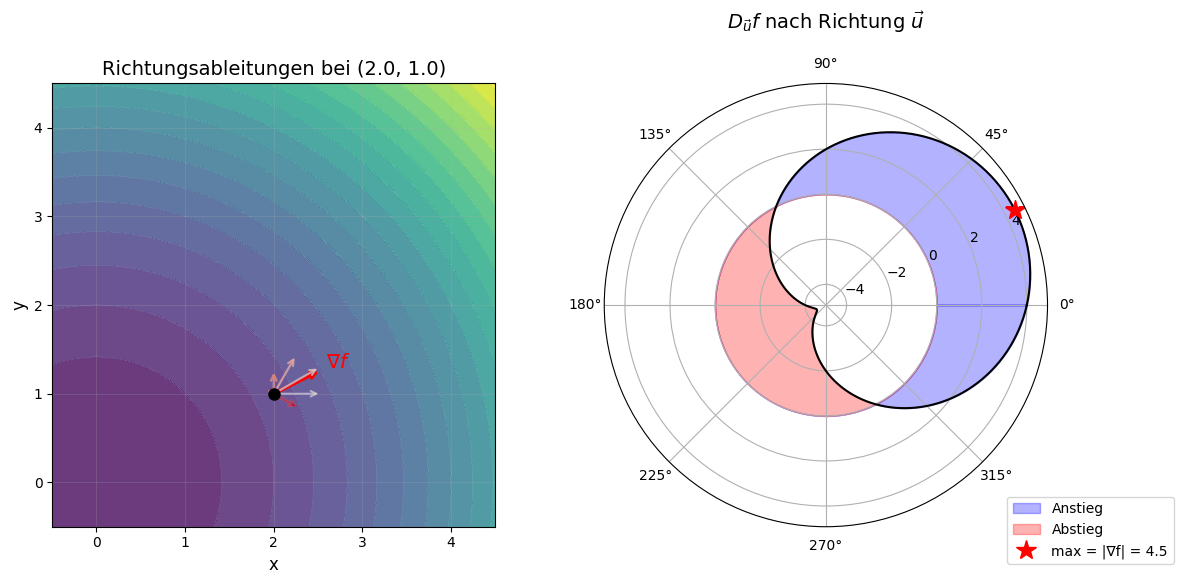

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ── Funktion und Gradient ──
def f_xy(x, y):
    return x**2 + y**2

def grad_f(x, y):
    return np.array([2*x, 2*y])

# ── Konfiguration ──
Richtungsableitung_Config = {
    "punkt": (2.0, 1.0),
    "bereich": (-0.5, 4.5),
    "kontour_levels": 25,
    "n_richtungen": 12,
    "pfeil_laenge": 0.6,
    "figsize": (14, 6),
}

def visualisiere_richtungsableitung(config):
    """Zeigt Richtungsableitungen in verschiedene Richtungen an einem Punkt."""
    px, py = config["punkt"]
    grad = grad_f(px, py)
    grad_betrag = np.linalg.norm(grad)
    grad_einheit = grad / grad_betrag

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=config["figsize"])

    # ── Links: Konturplot mit Richtungspfeilen ──
    xv = np.linspace(*config["bereich"], 200)
    yv = np.linspace(*config["bereich"], 200)
    X, Y = np.meshgrid(xv, yv)
    Z = f_xy(X, Y)

    ax1.contourf(X, Y, Z, levels=config["kontour_levels"], cmap='viridis', alpha=0.8)
    ax1.contour(X, Y, Z, levels=config["kontour_levels"], colors='white', linewidths=0.3, alpha=0.5)

    # Gradient (rot, dick)
    L = config["pfeil_laenge"]
    ax1.annotate('', xy=(px + L*grad_einheit[0], py + L*grad_einheit[1]),
                 xytext=(px, py),
                 arrowprops=dict(arrowstyle='->', color='red', lw=2.5))
    ax1.annotate(r'$\nabla f$', xy=(px + L*grad_einheit[0]*1.1, py + L*grad_einheit[1]*1.1),
                 fontsize=14, color='red', fontweight='bold')

    # Richtungsableitungen in verschiedene Richtungen
    winkel = np.linspace(0, 2*np.pi, config["n_richtungen"], endpoint=False)
    farben = plt.cm.coolwarm(np.linspace(0, 1, len(winkel)))

    richtungsabl_werte = []
    for i, phi in enumerate(winkel):
        u = np.array([np.cos(phi), np.sin(phi)])
        D_u = np.dot(grad, u)
        richtungsabl_werte.append(D_u)
        # Pfeillänge proportional zur Richtungsableitung (normiert)
        skalierung = D_u / grad_betrag * L
        if abs(skalierung) > 0.02:
            ax1.annotate('', xy=(px + skalierung*u[0], py + skalierung*u[1]),
                         xytext=(px, py),
                         arrowprops=dict(arrowstyle='->', color=farben[i], lw=1.5, alpha=0.7))

    ax1.plot(px, py, 'ko', markersize=8, zorder=5)
    ax1.set_title(f'Richtungsableitungen bei ({px}, {py})', fontsize=14)
    ax1.set_xlabel('x', fontsize=12)
    ax1.set_ylabel('y', fontsize=12)
    ax1.set_aspect('equal')
    ax1.grid(True, alpha=0.2)

    # ── Rechts: Polarplot der Richtungsableitung ──
    winkel_fein = np.linspace(0, 2*np.pi, 200)
    D_u_fein = [np.dot(grad, [np.cos(phi), np.sin(phi)]) for phi in winkel_fein]

    ax2_polar = fig.add_subplot(122, projection='polar')
    ax1.set_position([0.05, 0.1, 0.4, 0.8])
    ax2.remove()

    # Positive Werte blau, negative rot
    D_u_arr = np.array(D_u_fein)
    ax2_polar.fill_between(winkel_fein, 0, np.maximum(D_u_arr, 0),
                           alpha=0.3, color='blue', label='Anstieg')
    ax2_polar.fill_between(winkel_fein, 0, np.minimum(D_u_arr, 0),
                           alpha=0.3, color='red', label='Abstieg')
    ax2_polar.plot(winkel_fein, D_u_fein, color='black', linewidth=1.5)

    # Markiere Maximum (Gradientrichtung)
    grad_winkel = np.arctan2(grad[1], grad[0])
    ax2_polar.plot(grad_winkel, grad_betrag, 'r*', markersize=15, label=f'max = |∇f| = {grad_betrag:.1f}')

    ax2_polar.set_title(r'$D_{\vec{u}} f$ nach Richtung $\vec{u}$', fontsize=14, pad=20)
    ax2_polar.legend(loc='lower right', fontsize=10, bbox_to_anchor=(1.3, -0.1))

    plt.tight_layout()
    plt.show()

visualisiere_richtungsableitung(Richtungsableitung_Config)

**Zur Grafik:** Am Punkt $(2, 1)$ ist $\nabla f = (4, 2)$ mit $|\nabla f| \approx 4{,}47$.

- **Maximale Steigung** $= |\nabla f|$: in Richtung des Gradienten (roter Pfeil)
- **Minimale Steigung** $= -|\nabla f|$: entgegen dem Gradienten
- **Steigung $= 0$**: senkrecht zum Gradienten - das ist genau die Richtung entlang der **Höhenlinie**

Im Polarplot rechts sieht man das als Cosinuskurve: $D_{\vec u} f = \nabla f \cdot \vec u = |\nabla f| \cos\alpha$, wobei $\alpha$ der Winkel zwischen $\vec u$ und $\nabla f$ ist.

### 4. Die Jacobi-Matrix - Ableitung einer vektorwertigen Funktion

Bisher haben wir Funktionen betrachtet, die **mehrere Eingaben** haben, aber **eine Ausgabe** liefern: $f: \mathbb{R}^n \to \mathbb{R}$ (z.B. Temperatur, Kostenfunktion). Der Gradient $\nabla f$ war ein Vektor - das passt.

Aber was, wenn auch die **Ausgabe** mehrdimensional ist? Zum Beispiel:
- Eine **Koordinatentransformation** $(r, \theta) \mapsto (x, y)$ hat 2 Eingaben und 2 Ausgaben
- Ein **neuronales Netz** bildet einen Eingabevektor auf einen Ausgabevektor ab
- Eine **Strömung** ordnet jedem Punkt $(x, y)$ einen Geschwindigkeitsvektor $(v_x, v_y)$ zu

Für solche Funktionen $\vec F: \mathbb{R}^n \to \mathbb{R}^m$ brauchen wir eine **Matrix** als Ableitung. Das ist die **Jacobi-Matrix**.

#### Die Idee: Lineare Approximation verallgemeinern

Erinnern wir uns an die eindimensionale Analysis. Dort war die Ableitung $f'(a)$ die Steigung der **bestmöglichen linearen Approximation**:

$$f(a + h) \approx f(a) + f'(a) \cdot h$$

Das sagt: In der Nähe von $a$ verhält sich $f$ wie eine lineare Funktion. Die Zahl $f'(a)$ beschreibt, wie stark eine kleine Eingabeänderung $h$ das Ergebnis verändert.

Für eine vektorwertige Funktion $\vec F: \mathbb{R}^n \to \mathbb{R}^m$ suchen wir genau die gleiche Idee: Was ist die **bestmögliche lineare Approximation**?

$$\vec F(\vec a + \vec h) \approx \vec F(\vec a) + \underbrace{J}_{\text{Jacobi-Matrix}} \cdot \vec h$$

Die „Ableitung" ist jetzt keine einzelne Zahl mehr, sondern eine **Matrix** $J \in \mathbb{R}^{m \times n}$, die einen kleinen Eingabevektor $\vec h \in \mathbb{R}^n$ auf die resultierende Ausgabeänderung $\in \mathbb{R}^m$ abbildet. Das ist eine **lineare Abbildung** - genau wie in [02_Matrizen](../05_Vektoren_Matrizen/02_Matrizen.ipynb) gelernt.

#### Definition

Für $\vec F = \begin{pmatrix} F_1(x_1, \ldots, x_n) \\ \vdots \\ F_m(x_1, \ldots, x_n) \end{pmatrix}$ ist die Jacobi-Matrix:

$$J = \begin{pmatrix}
\frac{\partial F_1}{\partial x_1} & \frac{\partial F_1}{\partial x_2} & \cdots & \frac{\partial F_1}{\partial x_n} \\[6pt]
\frac{\partial F_2}{\partial x_1} & \frac{\partial F_2}{\partial x_2} & \cdots & \frac{\partial F_2}{\partial x_n} \\[6pt]
\vdots & \vdots & \ddots & \vdots \\[6pt]
\frac{\partial F_m}{\partial x_1} & \frac{\partial F_m}{\partial x_2} & \cdots & \frac{\partial F_m}{\partial x_n}
\end{pmatrix}$$

Jede **Zeile** enthält den Gradienten einer Komponentenfunktion $F_i$. Jede **Spalte** zeigt, wie sich alle Ausgaben ändern, wenn man **eine** Eingabe variiert.

#### Zusammenhang mit dem Gradienten

Für eine skalare Funktion $f: \mathbb{R}^n \to \mathbb{R}$ (also $m = 1$) hat die Jacobi-Matrix nur **eine Zeile** - das ist gerade der Gradient als Zeilenvektor:

$$J_f = \begin{pmatrix} \frac{\partial f}{\partial x_1} & \cdots & \frac{\partial f}{\partial x_n} \end{pmatrix} = (\nabla f)^T$$

| Funktion | Eingabe → Ausgabe | „Ableitung" | Dimension |
|---|---|---|---|
| $f: \mathbb{R} \to \mathbb{R}$ | Zahl → Zahl | $f'(x)$ (Zahl) | $1 \times 1$ |
| $f: \mathbb{R}^n \to \mathbb{R}$ | Vektor → Zahl | $\nabla f$ (Vektor) | $1 \times n$ |
| $\vec F: \mathbb{R}^n \to \mathbb{R}^m$ | Vektor → Vektor | $J$ (Matrix) | $m \times n$ |

#### Determinante der Jacobi-Matrix

Bei einer quadratischen Jacobi-Matrix ($m = n$) hat die **Determinante** eine anschauliche Bedeutung, die direkt an das anknüpft, was wir in [02_Matrizen](../05_Vektoren_Matrizen/02_Matrizen.ipynb) über Determinanten gelernt haben:

$$|\det(J)| = \text{lokaler Flächenskalierungsfaktor}$$

Das heißt: Wenn die Abbildung $\vec F$ ein kleines Flächenstück (oder Volumenelement) transformiert, wird dessen Fläche (Volumen) um den Faktor $|\det(J)|$ gestreckt oder gestaucht. Bei Polarkoordinaten zum Beispiel: $|\det(J)| = r$ - Flächenelemente weiter vom Ursprung entfernt werden stärker gestreckt.

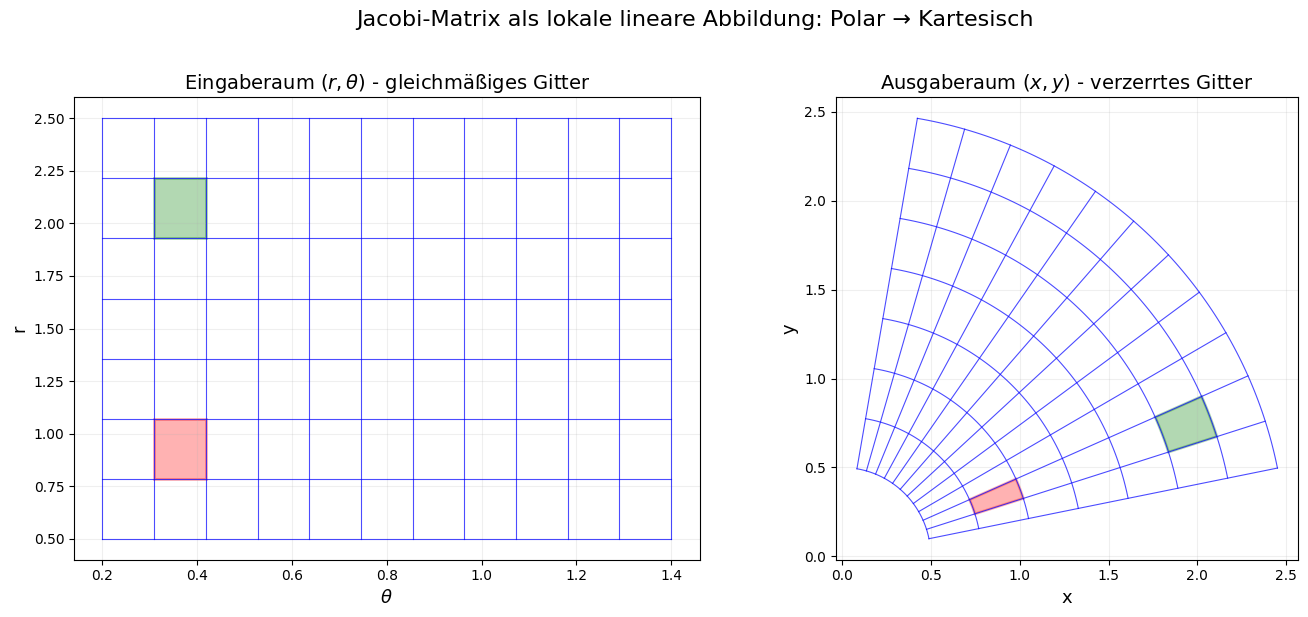

In [12]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# ── Symbolische Jacobi-Matrix: Polarkoordinaten ──
r, theta = sp.symbols('r theta')

F1 = r * sp.cos(theta)  # x = r·cos(θ)
F2 = r * sp.sin(theta)  # y = r·sin(θ)

# Jacobi-Matrix berechnen
J = sp.Matrix([
    [sp.diff(F1, r), sp.diff(F1, theta)],
    [sp.diff(F2, r), sp.diff(F2, theta)]
])

det_J = sp.simplify(J.det())

# ── Visualisierung: Wie die Jacobi-Matrix ein Gitter verzerrt ──
Jacobi_Config = {
    "r_bereich": (0.5, 2.5),
    "theta_bereich": (0.2, 1.4),
    "n_r": 8,
    "n_theta": 12,
    "figsize": (14, 6),
}

def visualisiere_jacobi_gitter(config):
    """Zeigt, wie die Polar→Kartesisch-Transformation ein Gitter verzerrt."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=config["figsize"])

    r_vals = np.linspace(*config["r_bereich"], config["n_r"])
    t_vals = np.linspace(*config["theta_bereich"], config["n_theta"])

    # ── Links: Gleichmäßiges Gitter in (r, θ)-Raum ──
    for rv in r_vals:
        ax1.plot([config["theta_bereich"][0], config["theta_bereich"][1]],
                 [rv, rv], 'b-', linewidth=0.8, alpha=0.7)
    for tv in t_vals:
        ax1.plot([tv, tv], [config["r_bereich"][0], config["r_bereich"][1]],
                 'b-', linewidth=0.8, alpha=0.7)

    # Markierung von zwei Zellen mit unterschiedlichem r
    from matplotlib.patches import Rectangle
    dr = r_vals[1] - r_vals[0]
    dt = t_vals[1] - t_vals[0]
    ax1.add_patch(Rectangle((t_vals[1], r_vals[1]), dt, dr,
                             facecolor='red', alpha=0.3, edgecolor='red', linewidth=2))
    ax1.add_patch(Rectangle((t_vals[1], r_vals[-3]), dt, dr,
                             facecolor='green', alpha=0.3, edgecolor='green', linewidth=2))

    ax1.set_xlabel(r'$\theta$', fontsize=13)
    ax1.set_ylabel('r', fontsize=13)
    ax1.set_title(r'Eingaberaum $(r, \theta)$ - gleichmäßiges Gitter', fontsize=14)
    ax1.grid(True, alpha=0.2)
    ax1.set_aspect('auto')

    # ── Rechts: Transformiertes Gitter in (x, y)-Raum ──
    # Konstante-r-Linien → Kreisbögen
    t_fein = np.linspace(*config["theta_bereich"], 100)
    for rv in r_vals:
        ax2.plot(rv * np.cos(t_fein), rv * np.sin(t_fein), 'b-', linewidth=0.8, alpha=0.7)

    # Konstante-θ-Linien → Strahlen
    r_fein = np.linspace(*config["r_bereich"], 100)
    for tv in t_vals:
        ax2.plot(r_fein * np.cos(tv), r_fein * np.sin(tv), 'b-', linewidth=0.8, alpha=0.7)

    # Transformierte Zellen (als gefüllte Flächen)
    for rv_idx, farbe in [(1, 'red'), (-3, 'green')]:
        rv_lo, rv_hi = r_vals[rv_idx], r_vals[rv_idx] + dr
        tv_lo, tv_hi = t_vals[1], t_vals[1] + dt
        tt = np.linspace(tv_lo, tv_hi, 50)
        xs = np.concatenate([rv_lo*np.cos(tt), rv_hi*np.cos(tt[::-1])])
        ys = np.concatenate([rv_lo*np.sin(tt), rv_hi*np.sin(tt[::-1])])
        ax2.fill(xs, ys, color=farbe, alpha=0.3, edgecolor=farbe, linewidth=2)

    ax2.set_xlabel('x', fontsize=13)
    ax2.set_ylabel('y', fontsize=13)
    ax2.set_title(r'Ausgaberaum $(x, y)$ - verzerrtes Gitter', fontsize=14)
    ax2.set_aspect('equal')
    ax2.grid(True, alpha=0.2)

    fig.suptitle('Jacobi-Matrix als lokale lineare Abbildung: Polar → Kartesisch',
                 fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

visualisiere_jacobi_gitter(Jacobi_Config)

**Ergebnis:** Für die Koordinatentransformation $(r, \theta) \to (x, y)$ mit $x = r\cos\theta$, $y = r\sin\theta$:

$$
J = \begin{pmatrix} \cos\theta & -r\sin\theta \\ \sin\theta & r\cos\theta \end{pmatrix}, \qquad \det(J) = r
$$

**Zur Grafik:** Gleichgroße Zellen im $(r, \theta)$-Raum (links) werden zu unterschiedlich großen Flächen im $(x, y)$-Raum (rechts). Die **grüne Zelle** (großes $r$) ist stärker gestreckt als die **rote** (kleines $r$) - genau um den Faktor $|\det(J)| = r$. Das ist der Grund, warum bei Polarintegration $dx\,dy = r\,dr\,d\theta$ gilt.

### 5. Die Hesse-Matrix - Krümmung in mehreren Dimensionen

In der eindimensionalen Analysis haben wir gelernt (in [04 – Höhere Ableitungen](../07_Analysis/04_Hoehere_Ableitungen_und_Kurvendiskussion.ipynb)): Die **zweite Ableitung** $f''(x)$ beschreibt die **Krümmung** einer Funktion:

- $f''(x) > 0$: Die Steigung nimmt zu → die Kurve krümmt sich **nach oben** (konvex / „Schüsselform")
- $f''(x) < 0$: Die Steigung nimmt ab → die Kurve krümmt sich **nach unten** (konkav / „Hügelform")
- $f''(x) = 0$: Möglicher **Wendepunkt**

Was passiert mit der Krümmung im Mehrdimensionalen? Bei $f(x, y)$ gibt es nicht mehr *eine* Krümmung, sondern die Krümmung **hängt von der Richtung ab**: Die Funktion kann in $x$-Richtung nach oben gekrümmt sein, aber in $y$-Richtung nach unten - das ergibt einen **Sattelpunkt**.

Um diese richtungsabhängige Krümmung vollständig zu beschreiben, brauchen wir eine **Matrix** aller zweiten partiellen Ableitungen: die **Hesse-Matrix**.

#### Definition

Für $f: \mathbb{R}^n \to \mathbb{R}$ ist die Hesse-Matrix die Matrix aller zweiten partiellen Ableitungen:

$$H_f = \begin{pmatrix}
\frac{\partial^2 f}{\partial x_1^2} & \frac{\partial^2 f}{\partial x_1 \partial x_2} & \cdots & \frac{\partial^2 f}{\partial x_1 \partial x_n} \\[6pt]
\frac{\partial^2 f}{\partial x_2 \partial x_1} & \frac{\partial^2 f}{\partial x_2^2} & \cdots & \frac{\partial^2 f}{\partial x_2 \partial x_n} \\[6pt]
\vdots & \vdots & \ddots & \vdots \\[6pt]
\frac{\partial^2 f}{\partial x_n \partial x_1} & \frac{\partial^2 f}{\partial x_n \partial x_2} & \cdots & \frac{\partial^2 f}{\partial x_n^2}
\end{pmatrix}$$

Für $f(x, y)$ konkret:

$$H_f = \begin{pmatrix}
f_{xx} & f_{xy} \\
f_{yx} & f_{yy}
\end{pmatrix}$$

#### Der Satz von Schwarz: Die Matrix ist symmetrisch

Eine wichtige Eigenschaft: Unter den üblichen Bedingungen (stetige zweite Ableitungen) gilt:

$$\frac{\partial^2 f}{\partial x \partial y} = \frac{\partial^2 f}{\partial y \partial x}$$

Die **Reihenfolge** des Ableitens spielt keine Rolle. Das bedeutet: Die Hesse-Matrix ist **symmetrisch** ($H = H^T$). Das ist nicht nur eine formale Eigenschaft - symmetrische Matrizen haben besonders „gutartige" Eigenwerte (alle reell), was für die Anwendung entscheidend ist.

#### Was die Einträge bedeuten

- **Diagonale** $f_{xx}$, $f_{yy}$: Krümmung entlang der Koordinatenachsen (wie $f''$ im 1D-Fall)
- **Nebendiagonale** $f_{xy}$: Misst, wie sich die Steigung in $x$-Richtung ändert, wenn man sich in $y$-Richtung bewegt - eine Art „Verdrehung" der Fläche

#### Klassifikation kritischer Punkte

An einem **kritischen Punkt** ($\nabla f = \vec 0$) bestimmt die Hesse-Matrix, ob es sich um ein Minimum, Maximum oder einen Sattel handelt. Die Schlüsselinformation steckt in den **Eigenwerten** $\lambda_1, \lambda_2$ der Hesse-Matrix:

| Eigenwerte | Geometrie | Typ |
|---|---|---|
| $\lambda_1 > 0,\ \lambda_2 > 0$ | Aufwärts gekrümmt in alle Richtungen | **Lokales Minimum** |
| $\lambda_1 < 0,\ \lambda_2 < 0$ | Abwärts gekrümmt in alle Richtungen | **Lokales Maximum** |
| $\lambda_1 > 0,\ \lambda_2 < 0$ | Aufwärts in einer, abwärts in anderer Richtung | **Sattelpunkt** |
| $\lambda_1 = 0$ oder $\lambda_2 = 0$ | Flach in mindestens einer Richtung | **Unbestimmt** (höhere Ableitungen nötig) |

> **Warum Eigenwerte?** Die Eigenwerte einer symmetrischen Matrix geben die Krümmung in den **Hauptkrümmungsrichtungen** an - den Richtungen, entlang denen die Krümmung am stärksten bzw. schwächsten ist. Die Eigenvektoren zeigen, *wo* diese Richtungen liegen. (Eigenwerte werden in `09_Lineare_Algebra` ausführlich behandelt - hier genügt die Idee.)

Für 2×2 kann man statt der Eigenwerte auch die **Determinante** und die **Spur** (Summe der Diagonalelemente) verwenden:

$$\det(H) = f_{xx} f_{yy} - f_{xy}^2, \qquad \text{Spur}(H) = f_{xx} + f_{yy}$$

- $\det(H) > 0$ und $f_{xx} > 0$ → Minimum
- $\det(H) > 0$ und $f_{xx} < 0$ → Maximum
- $\det(H) < 0$ → Sattelpunkt
- $\det(H) = 0$ → keine Aussage

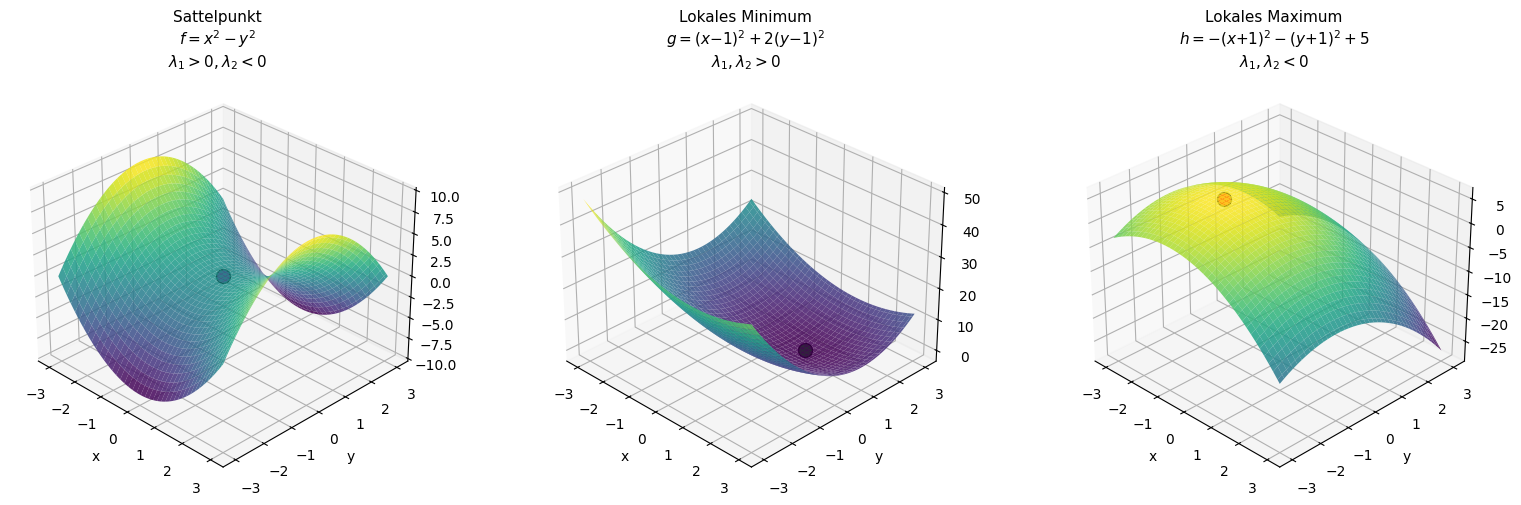

In [13]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ── Symbolische Hesse-Matrix ──
x, y = sp.symbols('x y')

# Drei Funktionen mit unterschiedlichen kritischen Punkten
funktionen = {
    "Sattelpunkt": {
        "f": x**2 - y**2,
        "name": r"$f(x,y) = x^2 - y^2$",
        "punkt": (0, 0),
    },
    "Minimum": {
        "f": (x - 1)**2 + 2*(y - 1)**2,
        "name": r"$g(x,y) = (x{-}1)^2 + 2(y{-}1)^2$",
        "punkt": (1, 1),
    },
    "Maximum": {
        "f": -(x + 1)**2 - (y + 1)**2 + 5,
        "name": r"$h(x,y) = -(x{+}1)^2 - (y{+}1)^2 + 5$",
        "punkt": (-1, -1),
    },
}

# ── 3D-Visualisierung der drei Typen ──
Hesse_Config = {
    "bereich": (-3, 3),
    "punkte": 80,
    "figsize": (16, 5),
    "blickwinkel": (30, -45),
}

def visualisiere_kritische_punkte(config):
    """Drei Flächen nebeneinander: Minimum, Maximum, Sattelpunkt."""
    xv = np.linspace(*config["bereich"], config["punkte"])
    yv = np.linspace(*config["bereich"], config["punkte"])
    X, Y = np.meshgrid(xv, yv)

    flaechen = [
        (X**2 - Y**2, "Sattelpunkt\n" + r"$f = x^2 - y^2$" + "\n" + r"$\lambda_1 > 0, \lambda_2 < 0$", (0, 0), 'purple'),
        ((X-1)**2 + 2*(Y-1)**2, "Lokales Minimum\n" + r"$g = (x{-}1)^2 + 2(y{-}1)^2$" + "\n" + r"$\lambda_1, \lambda_2 > 0$", (1, 1), 'green'),
        (-(X+1)**2 - (Y+1)**2 + 5, "Lokales Maximum\n" + r"$h = -(x{+}1)^2 - (y{+}1)^2 + 5$" + "\n" + r"$\lambda_1, \lambda_2 < 0$", (-1, -1), 'red'),
    ]

    fig = plt.figure(figsize=config["figsize"])

    for i, (Z, titel, punkt, farbe) in enumerate(flaechen):
        ax = fig.add_subplot(1, 3, i+1, projection='3d')
        ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.85)

        # Kritischer Punkt markieren
        px, py = punkt
        if i == 0: pz = px**2 - py**2
        elif i == 1: pz = (px-1)**2 + 2*(py-1)**2
        else: pz = -(px+1)**2 - (py+1)**2 + 5
        ax.scatter([px], [py], [pz], color=farbe, s=100, zorder=5, edgecolor='black')

        ax.set_title(titel, fontsize=11)
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.view_init(elev=config["blickwinkel"][0], azim=config["blickwinkel"][1])

    plt.tight_layout()
    plt.show()

visualisiere_kritische_punkte(Hesse_Config)

**Klassifikation der drei Beispiele:**

| Funktion | Punkt | Hesse-Matrix $H$ | Eigenwerte | $\det(H)$ | Typ |
|---|---|---|---|---|---|
| $f = x^2 - y^2$ | $(0, 0)$ | $\begin{pmatrix} 2 & 0 \\ 0 & -2 \end{pmatrix}$ | $+2, -2$ | $-4 < 0$ | **Sattelpunkt** |
| $g = (x{-}1)^2 + 2(y{-}1)^2$ | $(1, 1)$ | $\begin{pmatrix} 2 & 0 \\ 0 & 4 \end{pmatrix}$ | $+2, +4$ | $8 > 0$ | **Minimum** |
| $h = -(x{+}1)^2 - (y{+}1)^2 + 5$ | $(-1, -1)$ | $\begin{pmatrix} -2 & 0 \\ 0 & -2 \end{pmatrix}$ | $-2, -2$ | $4 > 0$ | **Maximum** |

Die Eigenwerte der Hesse-Matrix entscheiden: alle positiv → Minimum (Schüssel), alle negativ → Maximum (Hügel), gemischte Vorzeichen → Sattelpunkt (Pringles-Chip). Genau dafür brauchen wir Eigenwerte - Thema im nächsten Kapitel.

### 6. Gradient, Jacobi, Hesse - das Gesamtbild

Wir haben jetzt drei „Ableitungsobjekte" kennengelernt, die aufeinander aufbauen:

| Objekt | Funktion | Was es beschreibt | Form | Dimension |
|---|---|---|---|---|
| **Gradient** $\nabla f$ | $f: \mathbb{R}^n \to \mathbb{R}$ | Richtung und Stärke des steilsten Anstiegs | Vektor | $n$ |
| **Jacobi-Matrix** $J$ | $\vec F: \mathbb{R}^n \to \mathbb{R}^m$ | Beste lineare Approximation der Abbildung | Matrix | $m \times n$ |
| **Hesse-Matrix** $H$ | $f: \mathbb{R}^n \to \mathbb{R}$ | Krümmung / zweite Ordnung am Punkt | Symmetrische Matrix | $n \times n$ |

#### Zusammenhänge

1. Der **Gradient** ist ein Spezialfall der Jacobi-Matrix (eine Zeile, $m = 1$)
2. Die **Hesse-Matrix** ist die Jacobi-Matrix des Gradienten: $H_f = J_{\nabla f}$

> **Ausblick:** Diese drei Werkzeuge sind die Grundlage für Optimierungsverfahren wie Gradient Descent und Newtons Methode - Thema in `ml/01_Optimierung`.

---

## Verständnis-Check
*Löse die folgenden Aufgaben eigenständig, bevor du die Lösungen konsultierst.*

**Aufgabe 1 (Totale Ableitung):**
Gegeben: $f(x, y) = xy^2$, wobei $x(t) = e^t$ und $y(t) = \sin(t)$.

- a) Zeichne das Baumdiagramm der Abhängigkeiten.
- b) Berechne $\frac{dz}{dt}$ mit der multivariaten Kettenregel.
- c) Kontrolliere, indem Du $x(t)$ und $y(t)$ direkt einsetzt und nach $t$ ableitest.

**Aufgabe 2 (Richtungsableitung):**
Gegeben: $f(x, y) = x^2 + xy + y^2$ am Punkt $(1, 2)$.

- a) Berechne den Gradienten $\nabla f(1, 2)$.
- b) Berechne die Richtungsableitung in Richtung $\vec v = \begin{pmatrix}3\\4\end{pmatrix}$.
*(Tipp: Vergiss nicht, $\vec v$ zuerst zum Einheitsvektor zu normieren!)*
- c) In welcher Richtung ist die Richtungsableitung gleich null?

**Aufgabe 3 (Jacobi-Matrix):**
Gegeben die Abbildung $\vec F(u, v) = \begin{pmatrix} u^2 - v \\ u + v^2 \end{pmatrix}$.

- a) Bestimme die Jacobi-Matrix $J$.
- b) Berechne $J$ am Punkt $(1, 2)$ und $\det(J)$.
- c) Was sagt $|\det(J)|$ über die lokale Flächenskalierung an diesem Punkt?

**Aufgabe 4 (Hesse-Matrix):**
Gegeben: $f(x, y) = x^3 - 3xy + y^3$

- a) Finde alle kritischen Punkte (setze $\nabla f = \vec 0$).
- b) Berechne die Hesse-Matrix $H$.
- c) Klassifiziere jeden kritischen Punkt (Minimum, Maximum oder Sattel).

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

a) Baumdiagramm:
```
        z = f(x, y) = xy²
       /             \
     x(t) = eᵗ      y(t) = sin(t)
       \             /
            t
```

b) Kettenregel:
- $\frac{\partial f}{\partial x} = y^2$, $\frac{\partial f}{\partial y} = 2xy$
- $\frac{dx}{dt} = e^t$, $\frac{dy}{dt} = \cos(t)$
- $\frac{dz}{dt} = y^2 \cdot e^t + 2xy \cdot \cos(t) = \sin^2(t) \cdot e^t + 2e^t \sin(t) \cos(t)$
- Vereinfacht: $\frac{dz}{dt} = e^t \sin(t)[\sin(t) + 2\cos(t)]$

c) Direkt: $z(t) = e^t \cdot \sin^2(t)$
- $\frac{dz}{dt} = e^t \sin^2(t) + e^t \cdot 2\sin(t)\cos(t) = e^t[\sin^2(t) + 2\sin(t)\cos(t)]$ ✓

</details>

<details>
<summary>Lösung Aufgabe 2</summary>

a) $f(x,y) = x^2 + xy + y^2$
- $\frac{\partial f}{\partial x} = 2x + y$, $\frac{\partial f}{\partial y} = x + 2y$
- $\nabla f(1, 2) = (2 \cdot 1 + 2,\; 1 + 2 \cdot 2) = (4, 5)$

b) Einheitsvektor: $\vec u = \frac{1}{\sqrt{9+16}}\begin{pmatrix}3\\4\end{pmatrix} = \frac{1}{5}\begin{pmatrix}3\\4\end{pmatrix}$
- $D_{\vec u} f = \nabla f \cdot \vec u = 4 \cdot \frac{3}{5} + 5 \cdot \frac{4}{5} = \frac{12}{5} + \frac{20}{5} = \frac{32}{5} = 6{,}4$

c) $D_{\vec u} f = 0$ wenn $\vec u \perp \nabla f$, also $\vec u$ senkrecht auf $(4, 5)$.
Normalvektor: $\vec n = \frac{1}{\sqrt{41}}\begin{pmatrix}-5\\4\end{pmatrix}$ (oder umgekehrt). Das entspricht der **Höhenlinie** durch den Punkt.

</details>

<details>
<summary>Lösung Aufgabe 3</summary>

a) $J = \begin{pmatrix} \frac{\partial F_1}{\partial u} & \frac{\partial F_1}{\partial v} \\ \frac{\partial F_2}{\partial u} & \frac{\partial F_2}{\partial v} \end{pmatrix} = \begin{pmatrix} 2u & -1 \\ 1 & 2v \end{pmatrix}$

b) Bei $(1, 2)$: $J = \begin{pmatrix} 2 & -1 \\ 1 & 4 \end{pmatrix}$
- $\det(J) = 2 \cdot 4 - (-1) \cdot 1 = 8 + 1 = 9$

c) $|\det(J)| = 9$: Ein infinitesimales Flächenstück wird bei der Transformation am Punkt $(1, 2)$ um den Faktor 9 vergrößert.

</details>

<details>
<summary>Lösung Aufgabe 4</summary>

a) $\nabla f = (3x^2 - 3y,\; -3x + 3y^2) = \vec 0$
- Aus Gleichung 1: $y = x^2$
- In Gleichung 2: $-3x + 3x^4 = 0 \Rightarrow 3x(x^3 - 1) = 0$
- $x = 0 \Rightarrow y = 0$, oder $x = 1 \Rightarrow y = 1$
- Kritische Punkte: $(0, 0)$ und $(1, 1)$

b) $H = \begin{pmatrix} 6x & -3 \\ -3 & 6y \end{pmatrix}$

c) Bei $(0, 0)$: $H = \begin{pmatrix} 0 & -3 \\ -3 & 0 \end{pmatrix}$, $\det(H) = 0 - 9 = -9 < 0$ → **Sattelpunkt**

Bei $(1, 1)$: $H = \begin{pmatrix} 6 & -3 \\ -3 & 6 \end{pmatrix}$, $\det(H) = 36 - 9 = 27 > 0$ und $f_{xx} = 6 > 0$ → **Lokales Minimum**

</details>

---

## Zusammenfassung

| Konzept | Kernaussage |
|---------|-------------|
| **Totale Ableitung** | $\frac{dz}{dt} = \sum_i \frac{\partial f}{\partial x_i} \cdot \frac{dx_i}{dt}$ - summiere Beiträge aller Abhängigkeitspfade |
| **Multivariate Kettenregel** | Multipliziere entlang jedem Pfad im Baumdiagramm, addiere über alle Pfade |
| **Richtungsableitung** | $D_{\vec u} f = \nabla f \cdot \vec u$ - Steigung in beliebiger Richtung; der Gradient ist die maximale |
| **Jacobi-Matrix** | Die „Ableitung" einer vektorwertigen Funktion: $\vec F(\vec a + \vec h) \approx \vec F(\vec a) + J \vec h$ |
| **$\|\det(J)\|$** | Lokaler Flächen-/Volumenskalierungsfaktor der Abbildung |
| **Hesse-Matrix** | Matrix aller zweiten partiellen Ableitungen; beschreibt Krümmung am Punkt |
| **Kritische Punkte (2D)** | $\det(H) > 0 \wedge f_{xx} > 0$ → Min; $\det(H) > 0 \wedge f_{xx} < 0$ → Max; $\det(H) < 0$ → Sattel |

> **Nächster Schritt:** Die Hesse-Matrix nutzt Eigenwerte zur Klassifikation - was sind Eigenwerte und wie berechnet man sie? → Weiter zu `09_Lineare_Algebra/`

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Totale Ableitung | Total derivative |
| Totales Differential | Total differential |
| Multivariate Kettenregel | Multivariable chain rule |
| Baumdiagramm (Abhängigkeiten) | Dependency tree diagram |
| Richtungsableitung | Directional derivative |
| Jacobi-Matrix | Jacobian matrix |
| Determinante der Jacobi-Matrix | Jacobian determinant |
| Hesse-Matrix | Hessian matrix |
| Satz von Schwarz | Symmetry of second derivatives / Clairaut's theorem |
| Sattelpunkt | Saddle point |
| Krümmung | Curvature |
| Eigenwert | Eigenvalue |
| Lokales Minimum / Maximum | Local minimum / maximum |